[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/gianni04/option-pricing-python/blob/main/04_barrier_option.ipynb)

# 4. Barrier option

A **down-and-out call** is a normal call that disappears if the stock ever falls below a barrier
H. It is cheaper than a normal call. Priced two ways:

1. Monte Carlo: simulate price paths, set the payoff to zero if a path touches the barrier.
2. Closed-form formula (continuous barrier, H below the strike).

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import norm

In [2]:
def bs_price(S, K, T, r, sigma, kind="call"):
    d1 = (np.log(S / K) + (r + 0.5 * sigma**2) * T) / (sigma * np.sqrt(T))
    d2 = d1 - sigma * np.sqrt(T)
    if kind == "call":
        return S * norm.cdf(d1) - K * np.exp(-r * T) * norm.cdf(d2)
    return K * np.exp(-r * T) * norm.cdf(-d2) - S * norm.cdf(-d1)

In [3]:
def down_and_out_call(S, K, H, T, r, sigma):
    """Closed-form price, barrier watched continuously, H <= K."""
    lam = (r + 0.5 * sigma**2) / sigma**2
    y = np.log(H**2 / (S * K)) / (sigma * np.sqrt(T)) + lam * sigma * np.sqrt(T)
    down_and_in = (S * (H / S) ** (2 * lam) * norm.cdf(y)
                   - K * np.exp(-r * T) * (H / S) ** (2 * lam - 2) * norm.cdf(y - sigma * np.sqrt(T)))
    return bs_price(S, K, T, r, sigma, "call") - down_and_in

def mc_down_and_out(S, K, H, T, r, sigma, n_paths=100_000, n_steps=252, seed=1):
    rng = np.random.default_rng(seed)
    dt = T / n_steps
    z = rng.standard_normal((n_paths, n_steps))
    paths = S * np.exp(np.cumsum((r - 0.5 * sigma**2) * dt + sigma * np.sqrt(dt) * z, axis=1))
    alive = paths.min(axis=1) > H
    payoff = np.where(alive, np.maximum(paths[:, -1] - K, 0), 0)
    disc = np.exp(-r * T) * payoff
    return disc.mean(), 1.96 * disc.std() / np.sqrt(n_paths)

In [4]:
S, K, H, T, r, sigma = 100, 100, 90, 1.0, 0.03, 0.20

vanilla = bs_price(S, K, T, r, sigma, "call")
formula = down_and_out_call(S, K, H, T, r, sigma)
mc, ci = mc_down_and_out(S, K, H, T, r, sigma)

print(f"Normal call:              {vanilla:.4f}")
print(f"Down-and-out, formula:    {formula:.4f}")
print(f"Down-and-out, Monte Carlo {mc:.4f}  (95% interval +/- {ci:.4f}, barrier checked daily)")

Normal call:              9.4134
Down-and-out, formula:    7.7402
Down-and-out, Monte Carlo 8.0034  (95% interval +/- 0.0869, barrier checked daily)


The Monte Carlo price is a bit higher than the formula. The formula watches the barrier
continuously, the simulation only once a day, so some paths that cross the barrier between two
days survive. A known fix (Broadie, Glasserman and Kou) is to move the barrier down by
exp(-0.5826 sigma sqrt(dt)) in the formula to match daily monitoring.

In [5]:
dt = T / 252
H_adj = H * np.exp(-0.5826 * sigma * np.sqrt(dt))
print(f"Formula with the adjusted barrier: {down_and_out_call(S, K, H_adj, T, r, sigma):.4f}")
print(f"Monte Carlo (daily barrier):       {mc:.4f}")

Formula with the adjusted barrier: 7.9700
Monte Carlo (daily barrier):       8.0034


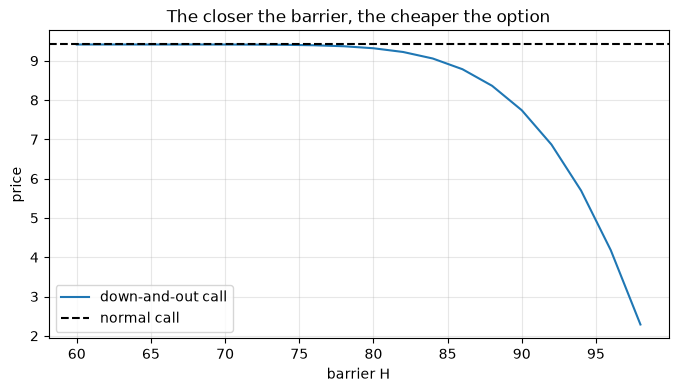

In [6]:
barriers = np.arange(60, 100, 2)
plt.figure(figsize=(8, 4))
plt.plot(barriers, [down_and_out_call(S, K, h, T, r, sigma) for h in barriers], label="down-and-out call")
plt.axhline(vanilla, color="k", ls="--", label="normal call")
plt.xlabel("barrier H"); plt.ylabel("price")
plt.title("The closer the barrier, the cheaper the option")
plt.legend(); plt.grid(alpha=0.3)
plt.show()